#### IMPORTS

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd()
if current_dir.name in ["@data_analysis", "data_analysis"]:
    os.chdir("..")

project_root = str(Path.cwd().resolve())
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from data_analysis.utils.label_distribution import plot_label_distribution
from data_analysis.utils.language_detection import split_languages_in_csv
from data_analysis.utils.text_analysis import TextAnalyzer
from data_analysis.utils.text_preprocessing import TextPreprocessor


/Users/sachagodey/Desktop/ETH/Computational_Inteligence_LAB/project/text_classifier/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-04-30 12:33:00,413	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


## 1. Distribution of the Data

#### Distribution Plot Generation

In [2]:
plot_label_distribution("data/train.csv", "data_analysis/img/output.png")

'data_analysis/img/output.png'

### Plot Visualisation

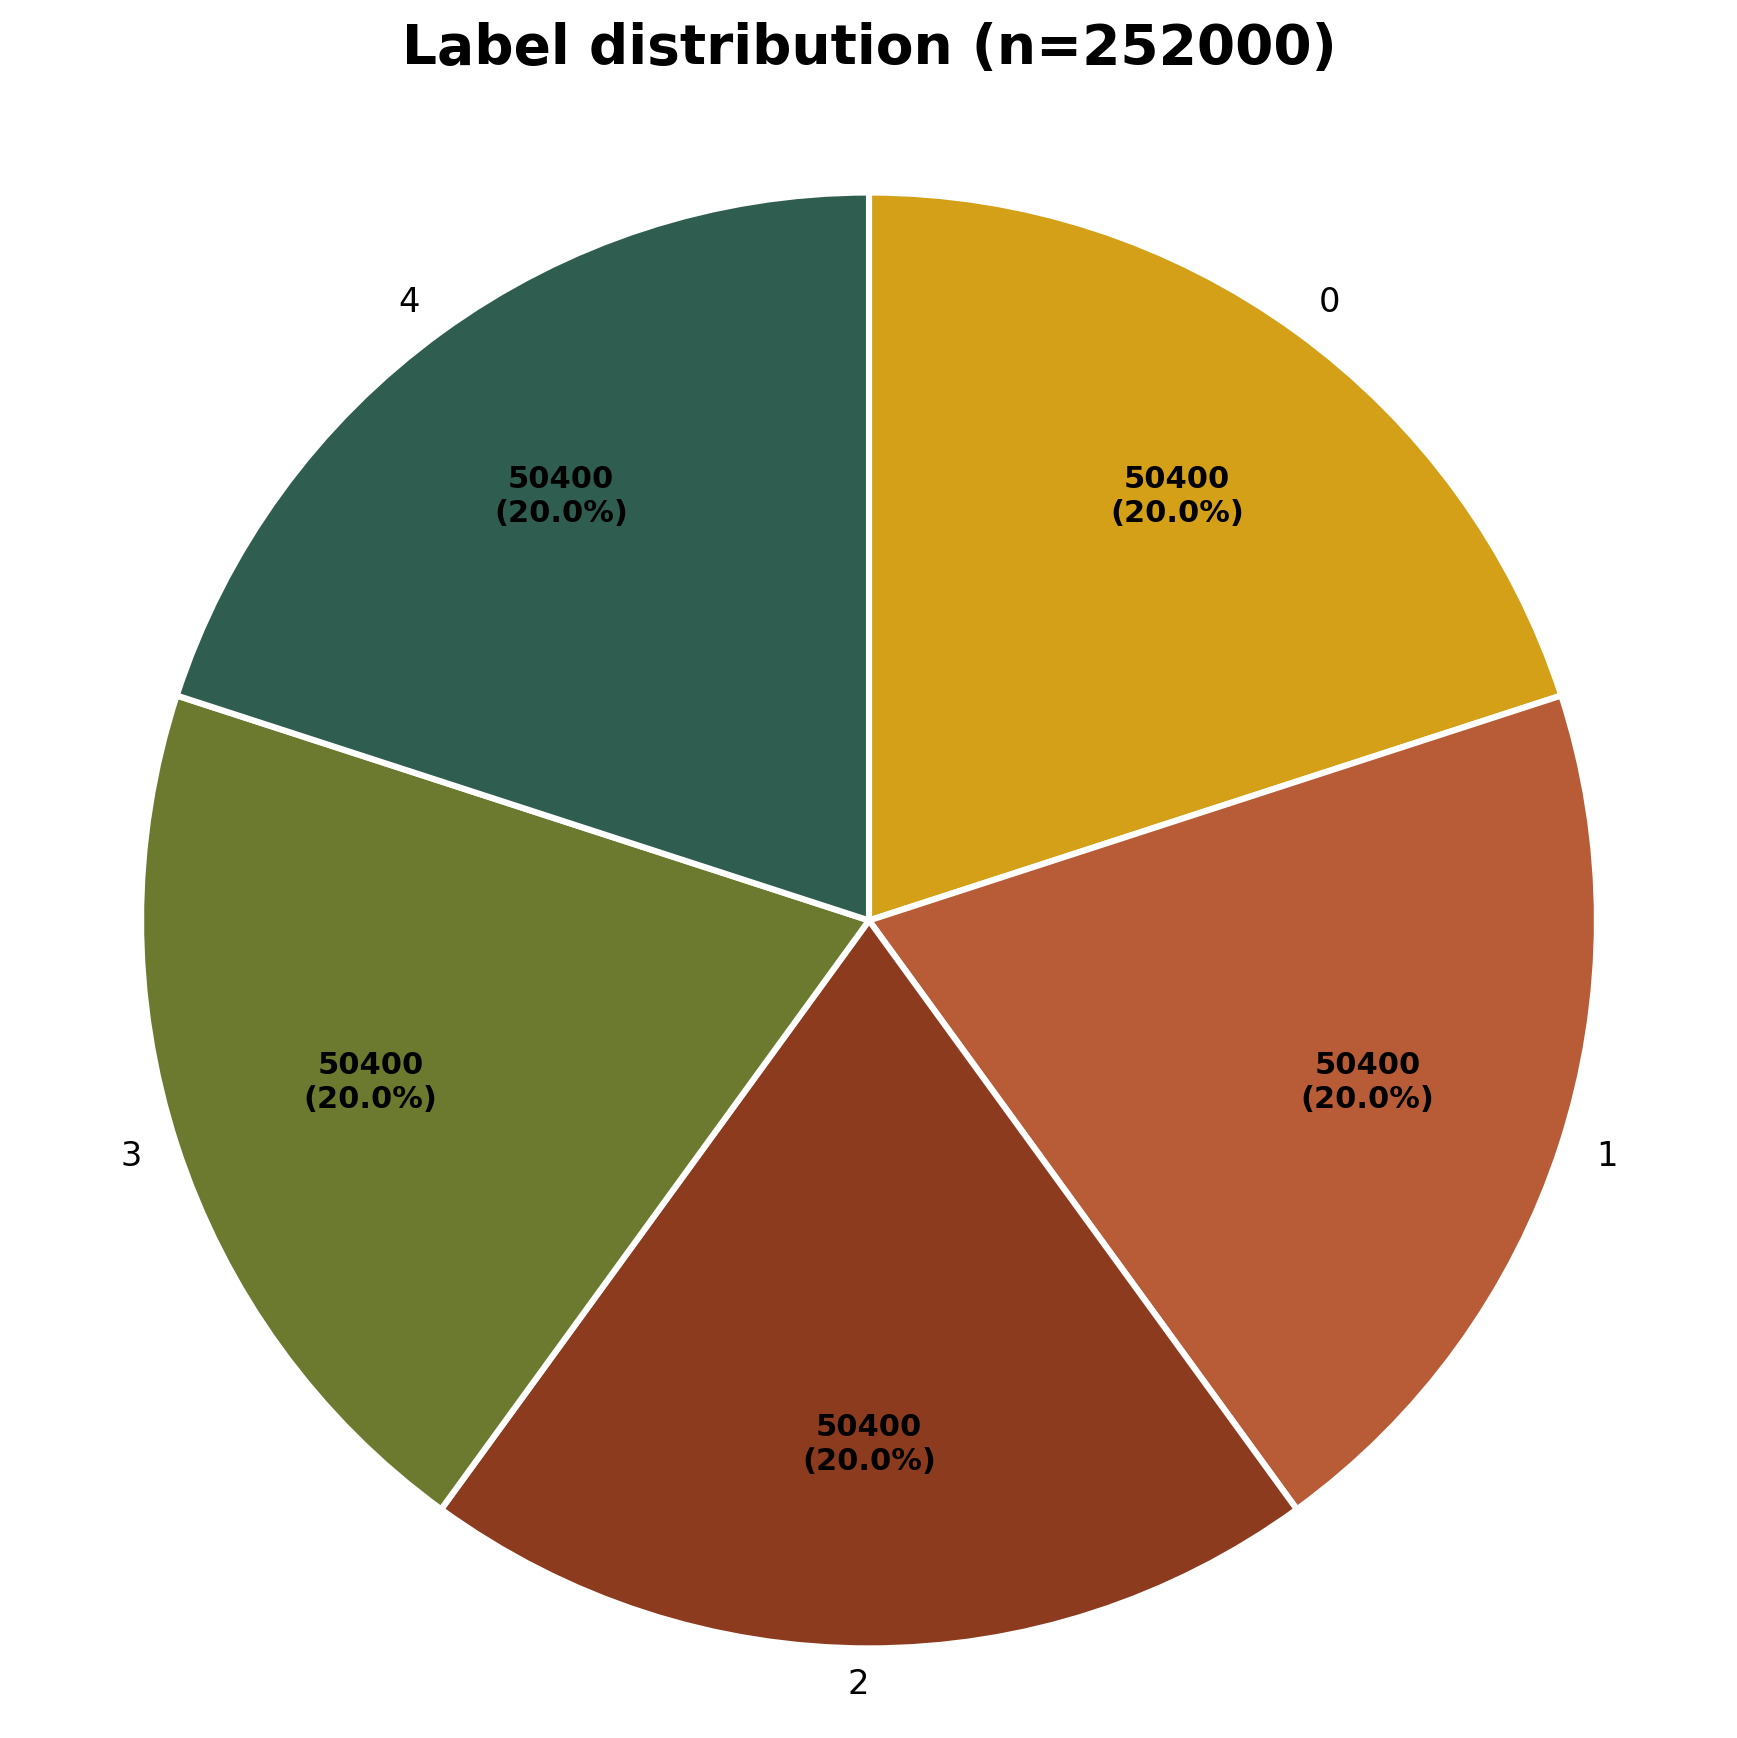

In [3]:
Image(filename="data_analysis/img/output.png", width = 600)

## Language Detection

### Generate the splits per langugage

In [ ]:
split_languages_in_csv(
    input_filepath="data/train.csv",
    text_column="sentence",
    output_dir="data/splitlang",
    confidence_threshold=0.63,
    debug=True
)


In [5]:
en = pd.read_csv("data/splitlang/EN/train.csv")
de = pd.read_csv("data/splitlang/DE/train.csv")
ambiguous = pd.read_csv("data/splitlang/AMBIGUOUS/train.csv")
debug = pd.read_csv("data/splitlang/DEBUG/train.csv")

In [6]:
plot_label_distribution("data/splitlang/EN/train.csv", "data_analysis/img/EN_label_distribution.png")
plot_label_distribution("data/splitlang/DE/train.csv", "data_analysis/img/DE_label_distribution.png")

'data_analysis/img/DE_label_distribution.png'

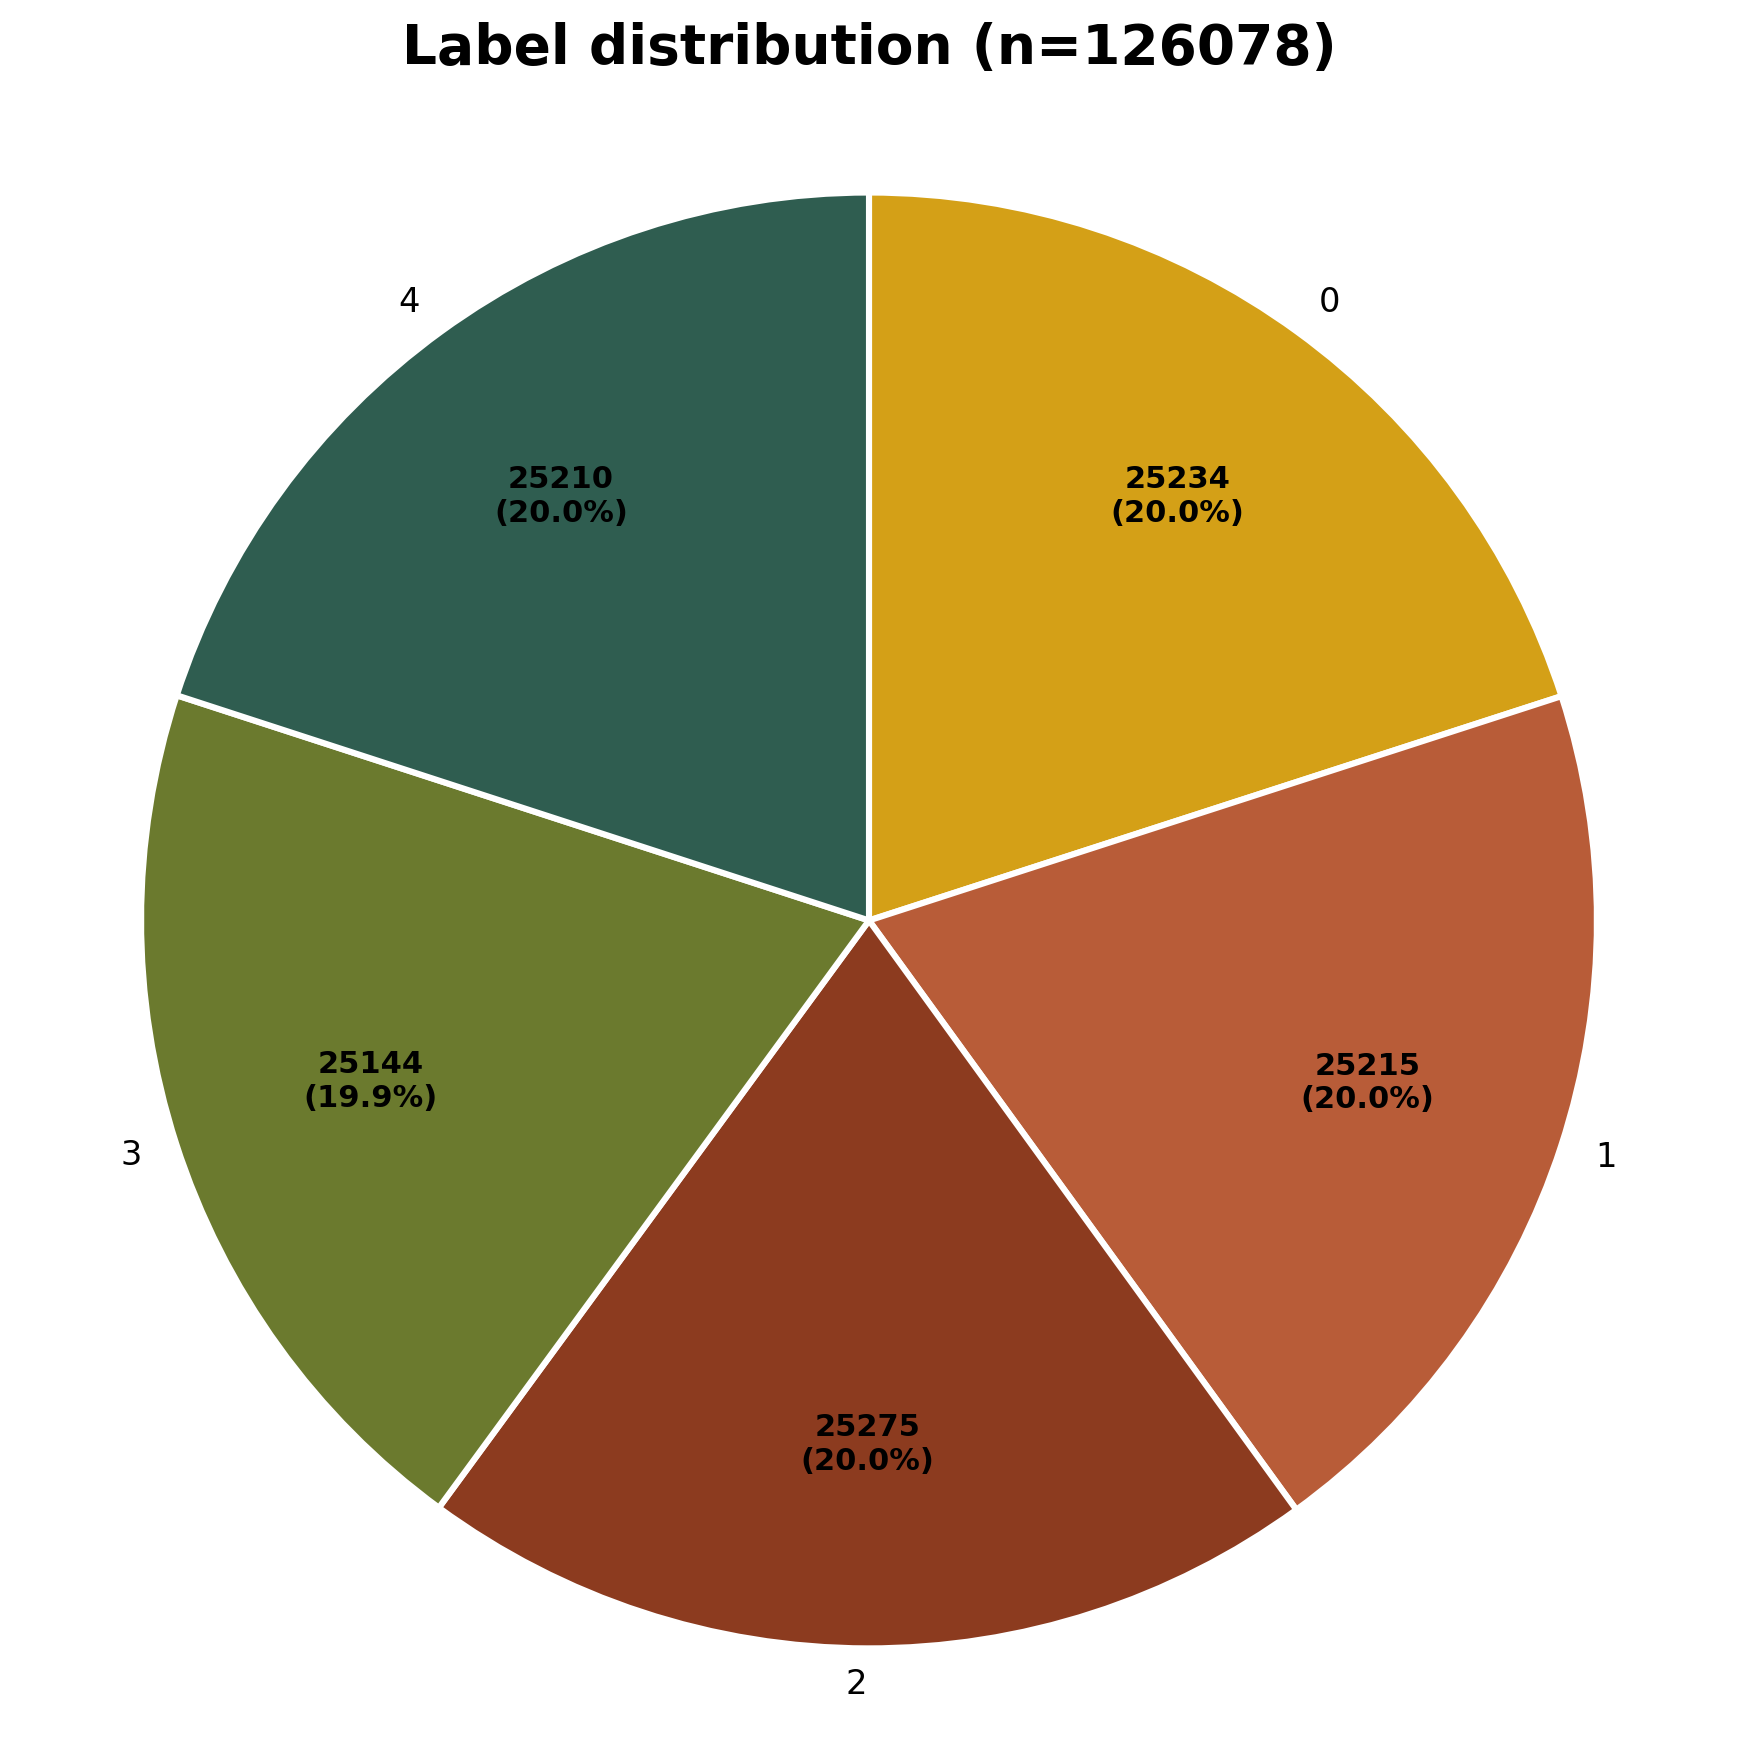

In [7]:
Image(filename="data_analysis/img/EN_label_distribution.png", width = 600)

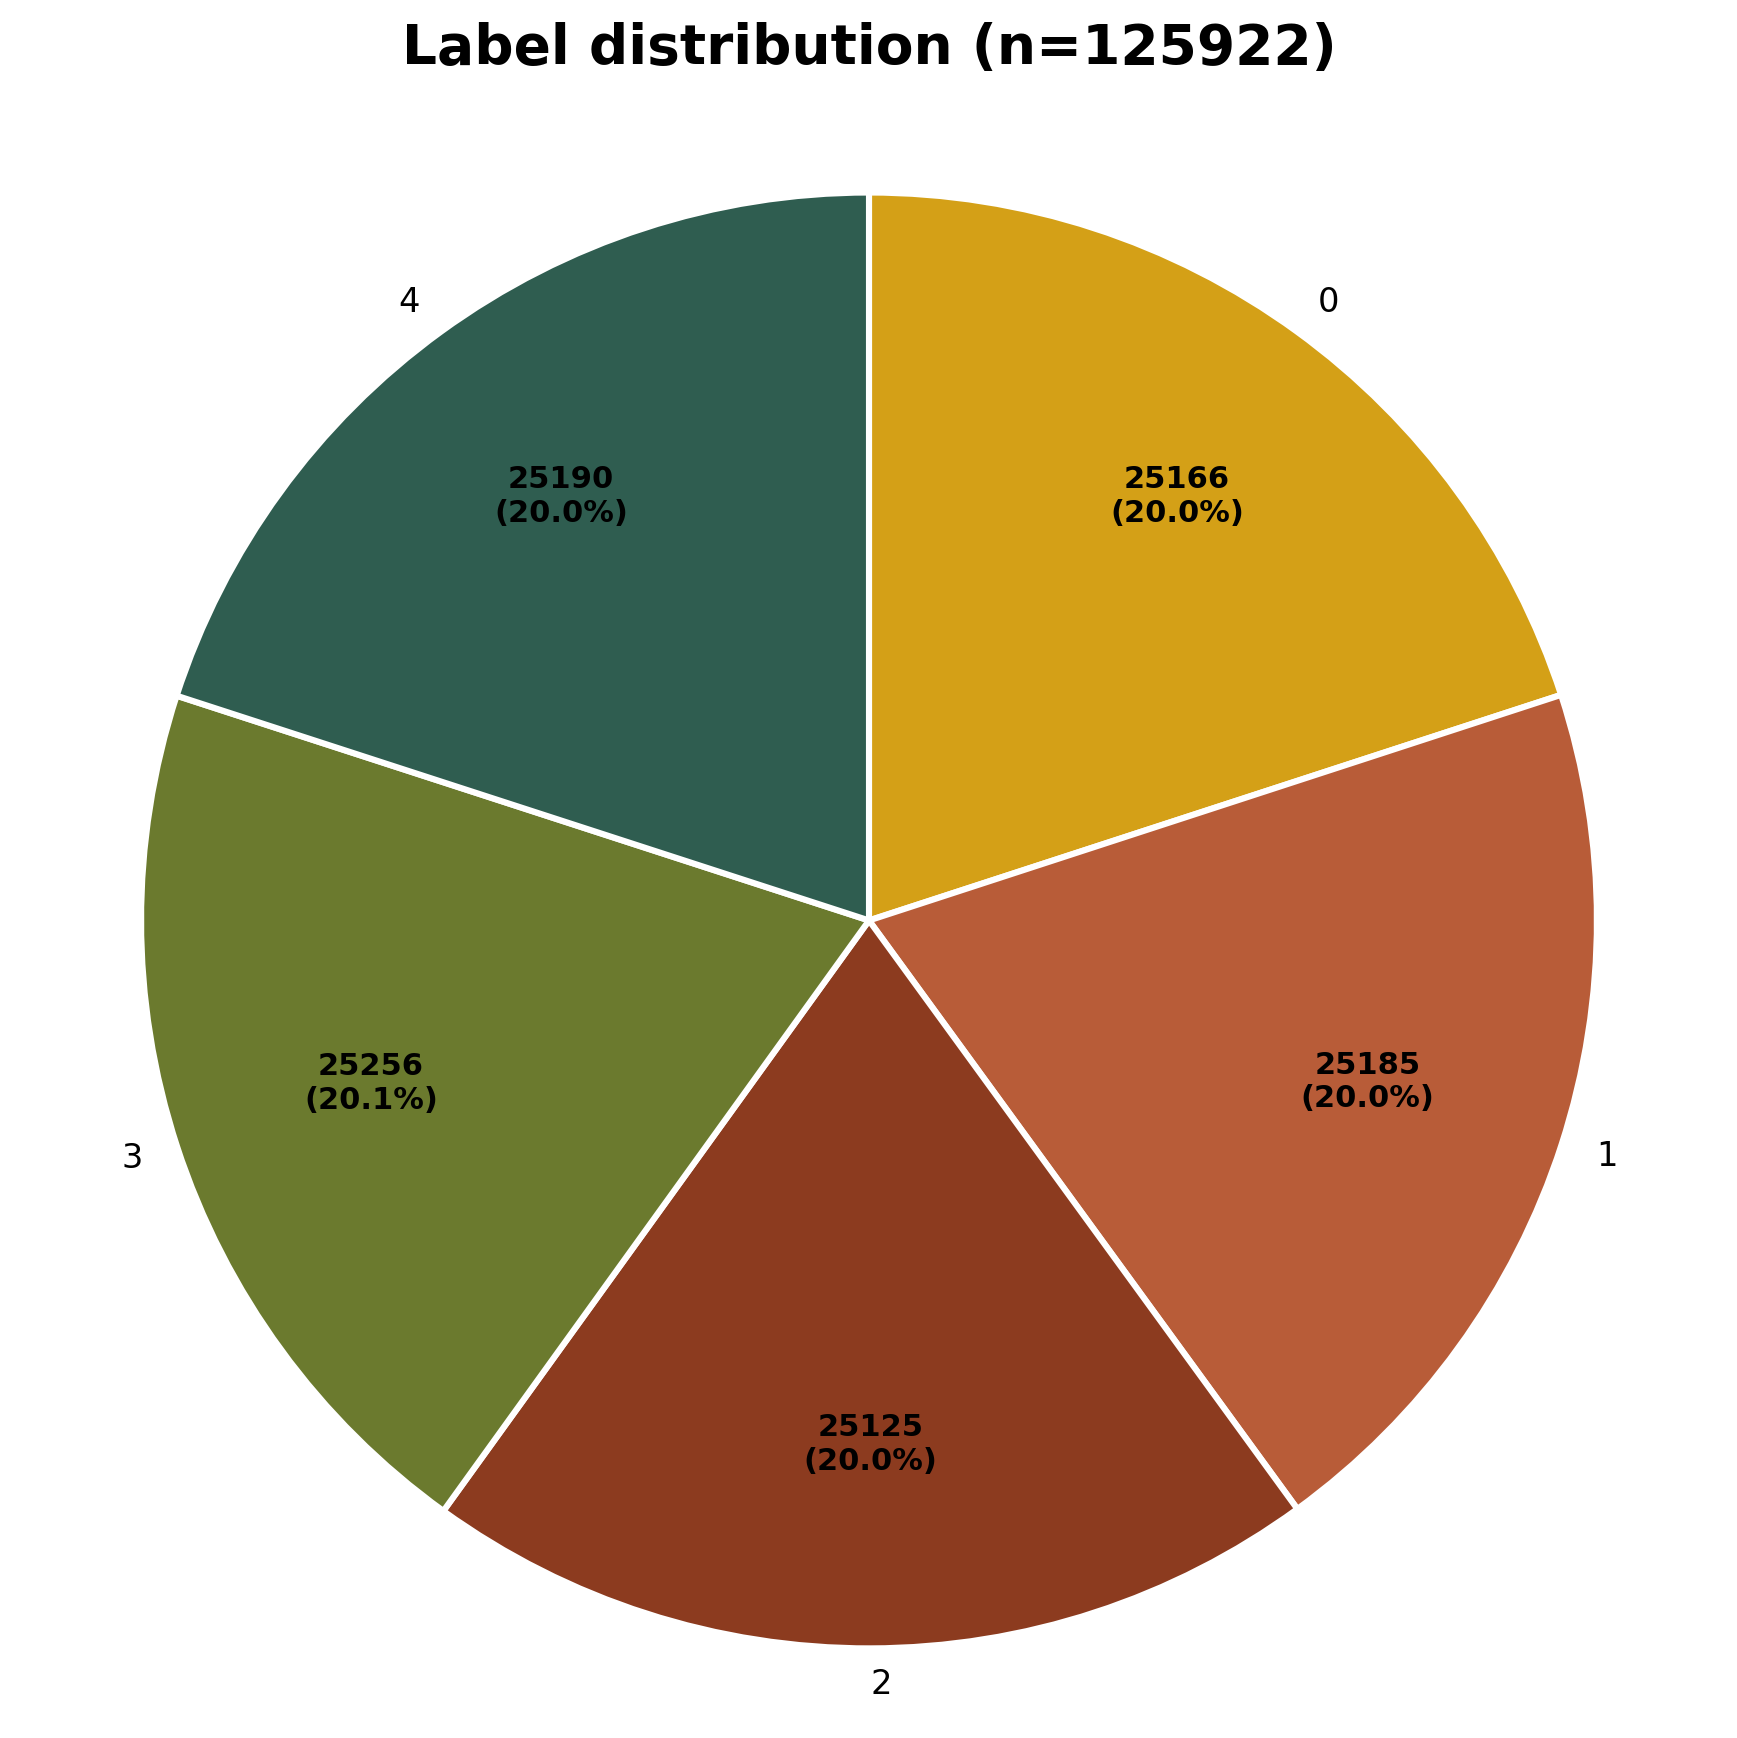

In [8]:
Image(filename="data_analysis/img/DE_label_distribution.png", width = 600)

## 3. Text Analysis Pipeline

In [ ]:
# Load the full debug CSV (requires split_languages_in_csv to have been run with debug=True)
debug_path = "data/splitlang/DEBUG/train.csv"
debug = pd.read_csv(debug_path)

import spacy

nlp_en = spacy.load("en_core_web_sm")
nlp_de = spacy.load("de_core_news_sm")

analyzer = TextAnalyzer(nlp={"EN": nlp_en, "DE": nlp_de}, sample_size=20000)

# --- Corpus overview ---
debug["_n_words"] = debug["sentence"].fillna("").str.split().str.len()
debug["_n_chars"] = debug["sentence"].fillna("").str.len()

print(f"docs            : {len(debug):,}   |   languages: {debug['_lang'].value_counts().to_dict()}")
print(f"labels          : {debug['label'].value_counts().sort_index().to_dict()}")
print(f"total tokens    : {int(debug['_n_words'].sum()):,}   ({debug['_n_words'].mean():.1f} per doc on avg)")
print(f"columns         : {debug.columns.tolist()}")

lang_palette = {"EN": "#4C72B0", "DE": "#DD8452"}
p99_words = float(debug["_n_words"].quantile(0.99))
p99_chars = float(debug["_n_chars"].quantile(0.99))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (0,0) Word-count histogram per language, x-axis capped at corpus p99
ax = axes[0, 0]
for lang, sub in debug.groupby("_lang"):
    ax.hist(sub["_n_words"], bins=60, range=(0, p99_words), alpha=0.6,
            label=f"{lang} (n={len(sub):,})",
            color=lang_palette.get(lang, "#888"), edgecolor="white")
ax.set_title(f"Word count per review (x-axis capped at corpus p99 = {p99_words:.0f})")
ax.set_xlabel("words")
ax.set_ylabel("docs")
ax.legend()

# (0,1) Char-count histogram per language, x-axis capped at corpus p99
ax = axes[0, 1]
for lang, sub in debug.groupby("_lang"):
    ax.hist(sub["_n_chars"], bins=60, range=(0, p99_chars), alpha=0.6,
            label=f"{lang} (n={len(sub):,})",
            color=lang_palette.get(lang, "#888"), edgecolor="white")
ax.set_title(f"Character count per review (x-axis capped at corpus p99 = {p99_chars:.0f})")
ax.set_xlabel("characters")
ax.set_ylabel("docs")
ax.legend()

# (1,0) Word-count CDF per language with p50 / p90 / p99 markers
ax = axes[1, 0]
for lang, sub in debug.groupby("_lang"):
    sorted_lens = np.sort(sub["_n_words"].values)
    cdf = np.arange(1, len(sorted_lens) + 1) / len(sorted_lens)
    ax.plot(sorted_lens, cdf, color=lang_palette.get(lang, "#888"),
            linewidth=2, label=lang)
    for q in (0.50, 0.90, 0.99):
        v = sub["_n_words"].quantile(q)
        ax.axvline(v, color=lang_palette.get(lang, "#888"),
                   linestyle="--", alpha=0.35, linewidth=1)
        ax.text(v, q, f" p{int(q*100)}={int(v)}",
                color=lang_palette.get(lang, "#888"),
                fontsize=8, va="center", ha="left")
ax.set_xlim(0, p99_words * 1.1)
ax.set_title("Word-count CDF (with p50 / p90 / p99 markers)")
ax.set_xlabel("words")
ax.set_ylabel("cumulative share of docs")
ax.legend()

# (1,1) Per-language length summary table — shorter column names to fit the cell
length_overview = (
    debug.groupby("_lang")
         .agg(n_docs=("sentence", "size"),
              w_mean=("_n_words", "mean"),
              w_p50=("_n_words", "median"),
              w_p90=("_n_words", lambda s: s.quantile(0.90)),
              w_p99=("_n_words", lambda s: s.quantile(0.99)),
              w_max=("_n_words", "max"),
              c_mean=("_n_chars", "mean"),
              c_p50=("_n_chars", "median"),
              c_max=("_n_chars", "max"))
         .round(1)
)
ax = axes[1, 1]
ax.axis("off")
table = ax.table(
    cellText=length_overview.reset_index().values,
    colLabels=["lang"] + length_overview.columns.tolist(),
    loc="center",
    cellLoc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.6)
ax.set_title("Per-language length summary  (w_* = words, c_* = characters)", pad=12)

plt.tight_layout()
plt.savefig("data_analysis/img/corpus_overview.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.1 Dataset size per language / class

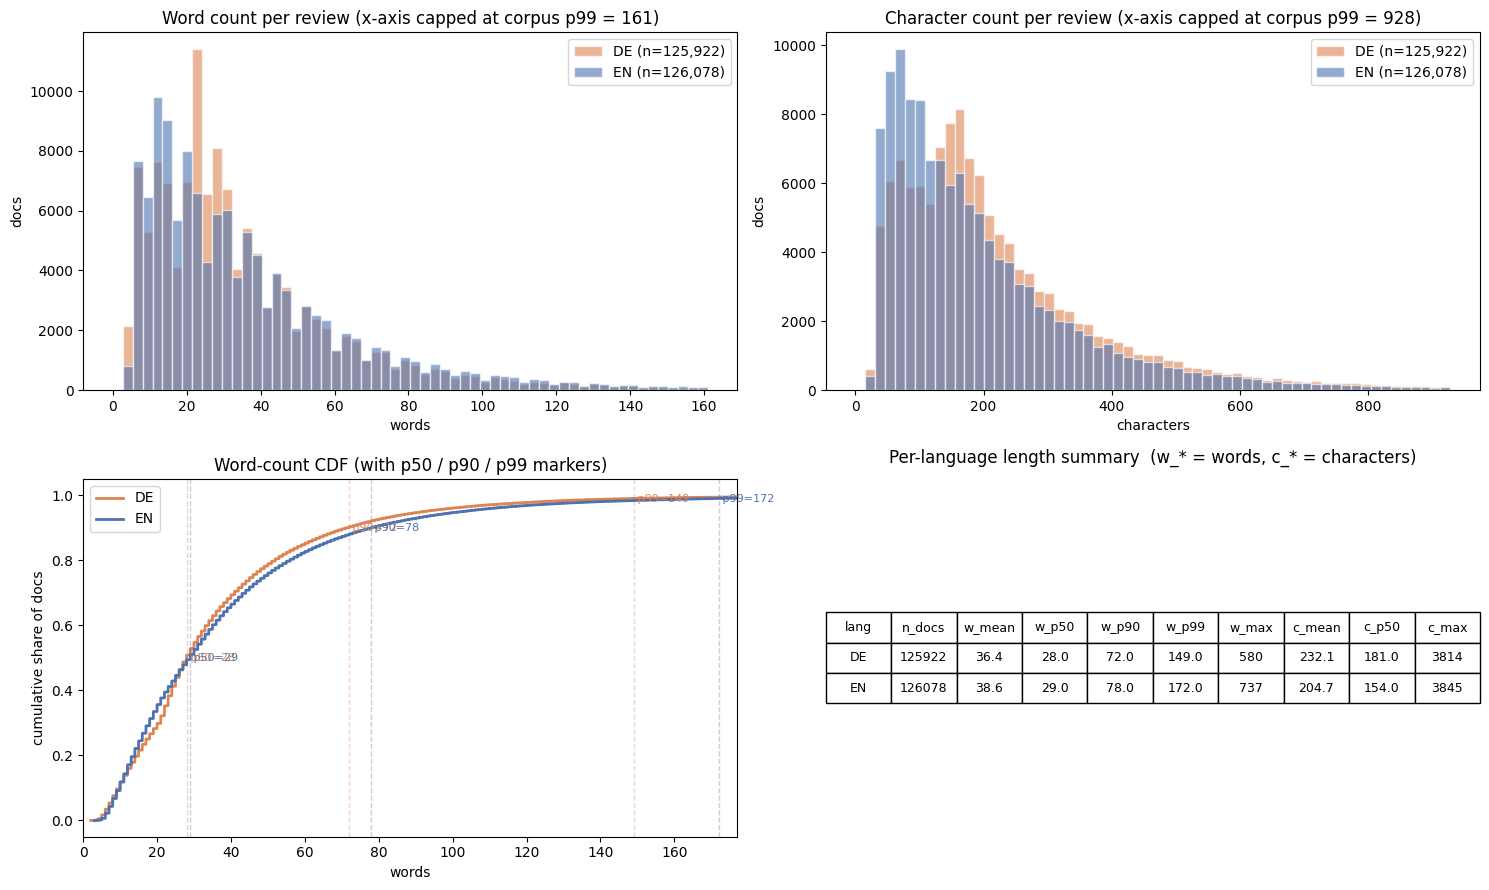

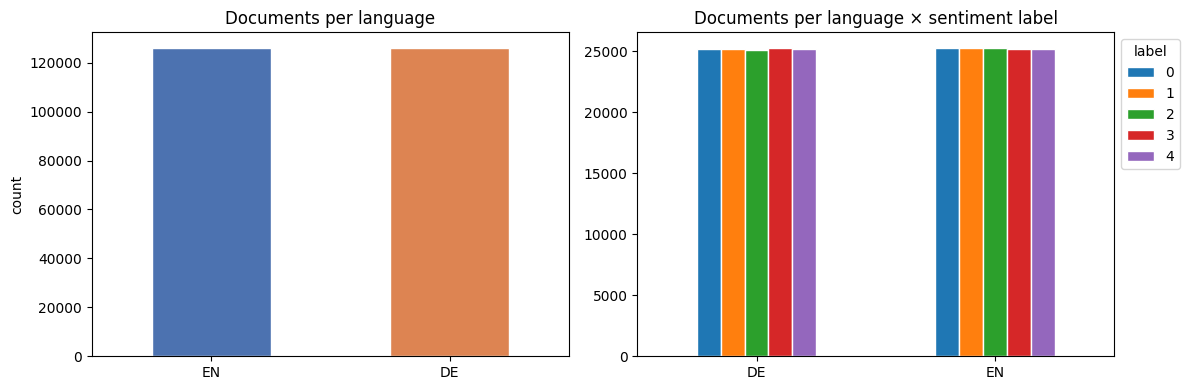

In [10]:
%matplotlib inline
lang_counts = debug['_lang'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: total per language
lang_counts.plot(kind='bar', ax=axes[0], color=['#4C72B0','#DD8452'], edgecolor='white')
axes[0].set_title('Documents per language')
axes[0].set_xlabel('')
axes[0].set_ylabel('count')
axes[0].tick_params(axis='x', rotation=0)

# Right: per language × label
lang_label = debug.groupby(['_lang','label']).size().unstack(fill_value=0)
lang_label.plot(kind='bar', ax=axes[1], edgecolor='white')
axes[1].set_title('Documents per language × sentiment label')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='label', bbox_to_anchor=(1,1))

plt.tight_layout()
plt.savefig('data_analysis/img/dataset_size.png', dpi=120, bbox_inches='tight')


### 3.2 Length distribution by (language, label)

Word count per review by sentiment label, split by language. Boxplots are
clipped at the 99th percentile within each language for readability.

Includes Spearman rank correlation between document length and label per
language — a non-zero ρ means longer (or shorter) reviews systematically
lean toward higher (or lower) ratings.

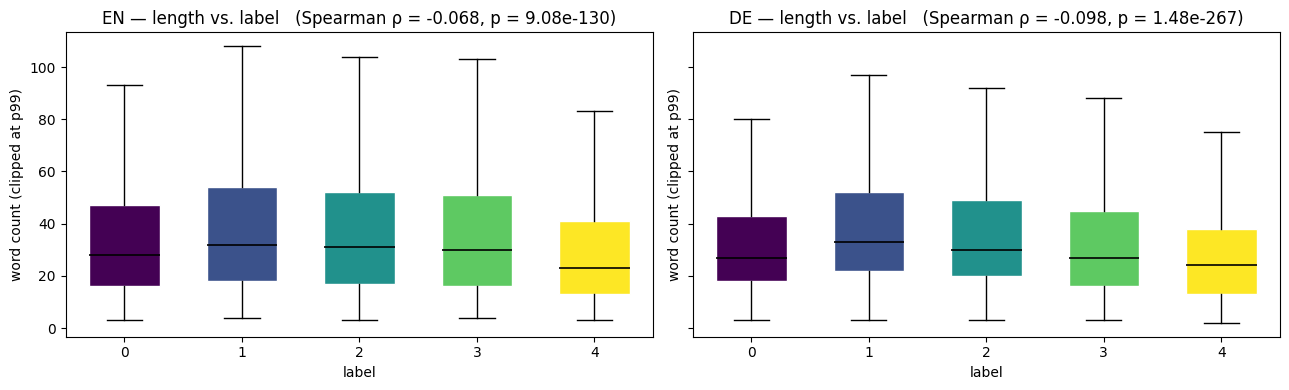

Spearman ρ(length, label) per language:
  DE: ρ = -0.0982   p = 1.48e-267   n = 125,922
  EN: ρ = -0.0682   p = 9.08e-130   n = 126,078


,lang,label,mean,median,p10,p90,n
0,DE,0,34.872884,27.0,11.0,67.0,25166
1,DE,1,41.311495,33.0,12.0,79.0,25185
2,DE,2,39.141214,30.0,11.0,75.6,25125
3,DE,3,35.919821,27.0,9.0,71.0,25256
4,DE,4,30.843549,24.0,8.0,62.1,25190
5,EN,0,36.942459,28.0,10.0,74.0,25234
6,EN,1,42.193298,32.0,11.0,85.0,25215
7,EN,2,40.900534,31.0,11.0,82.0,25275
8,EN,3,40.423123,30.0,10.0,82.0,25144
9,EN,4,32.422610,23.0,8.0,66.0,25210


In [11]:
length_stats, length_spearman = analyzer.length_by_label(
    debug, text_col="sentence", lang_col="_lang", label_col="label"
)

work = debug[["_lang", "label"]].copy()
work["length"] = debug["sentence"].fillna("").str.split().str.len()

cmap = plt.get_cmap("viridis")
labels_sorted = sorted(work["label"].unique())
colors = [cmap(i / max(len(labels_sorted) - 1, 1)) for i in range(len(labels_sorted))]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, lang in zip(axes, ["EN", "DE"]):
    sub = work[work["_lang"] == lang]
    p99 = sub["length"].quantile(0.99)
    by_label = [sub.loc[sub["label"] == lab, "length"].clip(upper=p99) for lab in labels_sorted]
    bp = ax.boxplot(
        by_label,
        positions=range(len(labels_sorted)),
        widths=0.6,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.2},
    )
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
        patch.set_edgecolor("white")
    ax.set_xticks(range(len(labels_sorted)))
    ax.set_xticklabels(labels_sorted)
    rho = length_spearman[lang]["rho"]
    p = length_spearman[lang]["pvalue"]
    ax.set_title(f"{lang} — length vs. label   (Spearman ρ = {rho:+.3f}, p = {p:.2e})")
    ax.set_xlabel("label")
    ax.set_ylabel("word count (clipped at p99)")

plt.tight_layout()
plt.savefig("data_analysis/img/length_by_label.png", dpi=120, bbox_inches="tight")
plt.show()

print("Spearman ρ(length, label) per language:")
for lang, v in length_spearman.items():
    print(f"  {lang}: ρ = {v['rho']:+.4f}   p = {v['pvalue']:.2e}   n = {v['n']:,}")

display(length_stats)

### 3.3 Distinctive vocabulary per (language, label)

Top-15 lemmas per (language × label) ranked by log-odds z-score with an
informative Dirichlet prior (Monroe, Colaresi, Quinn 2008). The whole-language
lemma distribution is the prior, so corpus-wide words (function words, neutral
adjectives) get smoothed away and only class-distinctive vocabulary surfaces.

Positive z (green bars) = over-represented in this label vs. the rest of the
same language; negative z (orange bars) = under-represented. Compare against
what the collaborator found for negation markers.

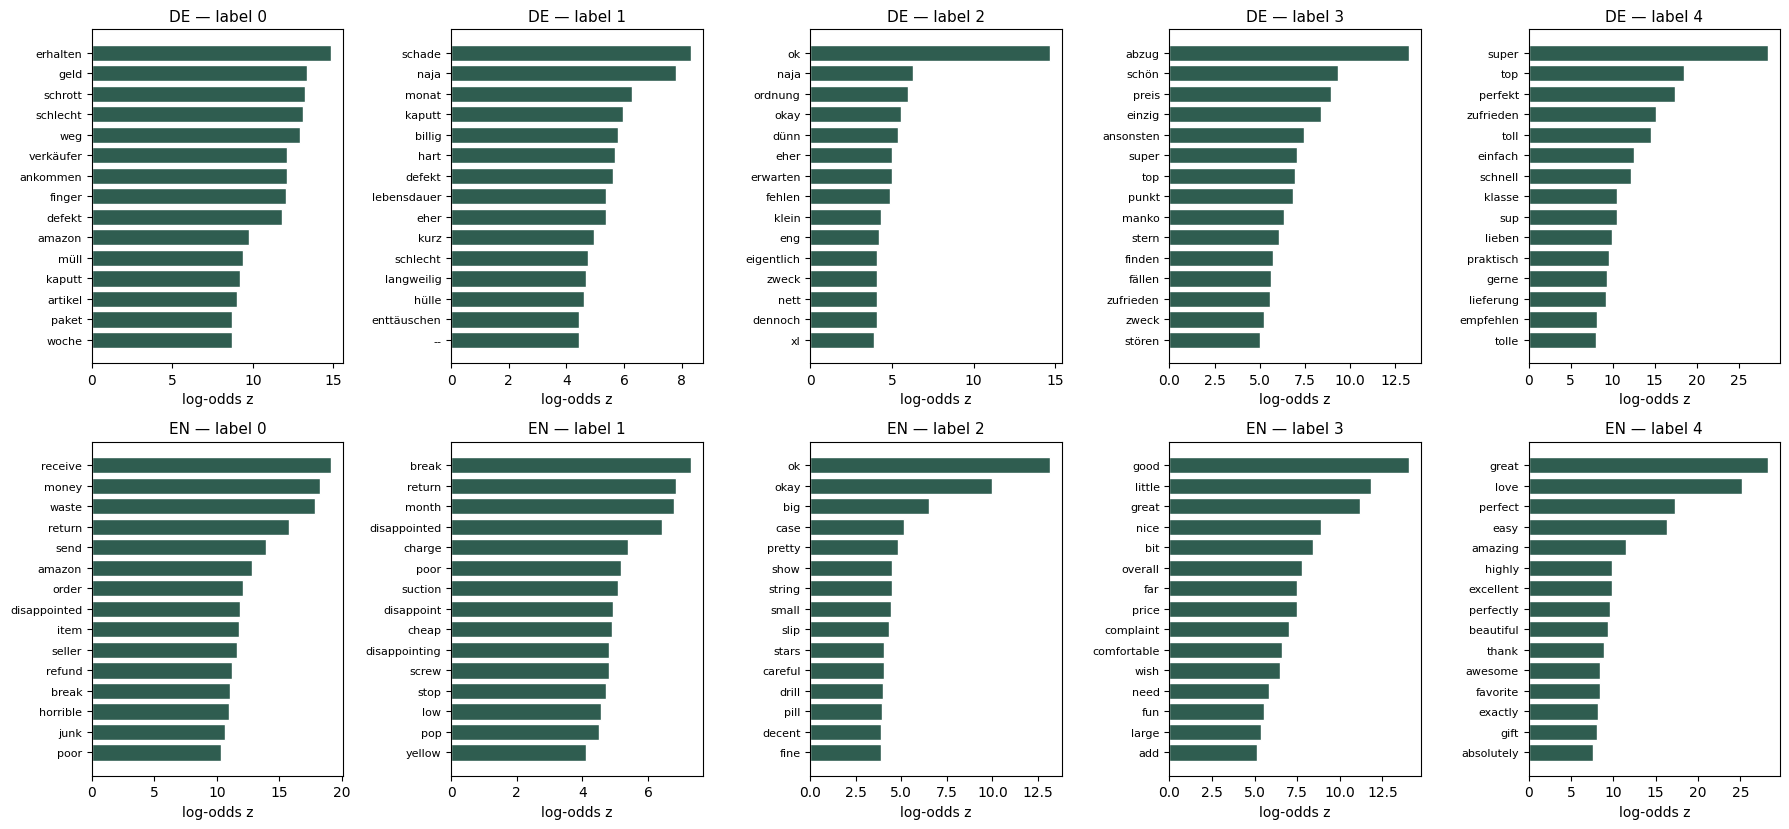

Top distinctive lemmas per (lang, label) — sorted by descending z:
  DE  label=0: erhalten, geld, schrott, schlecht, weg, verkäufer, ankommen, finger
  DE  label=1: schade, naja, monat, kaputt, billig, hart, defekt, lebensdauer
  DE  label=2: ok, naja, ordnung, okay, dünn, eher, erwarten, fehlen
  DE  label=3: abzug, schön, preis, einzig, ansonsten, super, top, punkt
  DE  label=4: super, top, perfekt, zufrieden, toll, einfach, schnell, klasse
  EN  label=0: receive, money, waste, return, send, amazon, order, disappointed
  EN  label=1: break, return, month, disappointed, charge, poor, suction, disappoint
  EN  label=2: ok, okay, big, case, pretty, show, string, small
  EN  label=3: good, little, great, nice, bit, overall, far, price
  EN  label=4: great, love, perfect, easy, amazing, highly, excellent, perfectly


,lang,label,lemma,z,count_in_label,count_total
0,DE,0,erhalten,14.892,166,273
1,DE,0,geld,13.399,186,378
2,DE,0,schrott,13.247,121,139
3,DE,0,schlecht,13.111,181,371
4,DE,0,weg,12.937,131,223
...,...,...,...,...,...,...
145,EN,4,awesome,8.422,61,119
146,EN,4,favorite,8.417,47,75
147,EN,4,exactly,8.243,74,165
148,EN,4,gift,8.075,84,203


In [12]:
distinctive = analyzer.distinctive_vocab(
    debug,
    text_col="sentence",
    lang_col="_lang",
    label_col="label",
    n=15,
    prior_alpha=0.01,
    min_count=10,
)

langs = sorted(distinctive["lang"].unique())
labels = sorted(distinctive["label"].unique())

fig, axes = plt.subplots(
    len(langs), len(labels),
    figsize=(3.6 * len(labels), 4.2 * len(langs)),
    sharex=False,
)
if len(langs) == 1:
    axes = np.array([axes])

for i, lang in enumerate(langs):
    for j, lab in enumerate(labels):
        ax = axes[i][j]
        sub = (distinctive[(distinctive["lang"] == lang) & (distinctive["label"] == lab)]
               .sort_values("z"))
        if sub.empty:
            ax.text(0.5, 0.5, "(empty)", ha="center", va="center",
                    transform=ax.transAxes)
            ax.set_axis_off()
            continue
        colors = ["#2F5D50" if z > 0 else "#B85C38" for z in sub["z"]]
        ax.barh(sub["lemma"], sub["z"], color=colors, edgecolor="white")
        ax.axvline(0, color="black", linewidth=0.6)
        ax.set_title(f"{lang} — label {lab}", fontsize=11)
        ax.set_xlabel("log-odds z")
        ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig("data_analysis/img/distinctive_vocab.png", dpi=120, bbox_inches="tight")
plt.show()

# Compact text view: top-8 distinctive lemmas per (lang, label) — easy to copy
print("Top distinctive lemmas per (lang, label) — sorted by descending z:")
for (lang, lab), grp in distinctive.groupby(["lang", "label"]):
    top = grp.sort_values("z", ascending=False).head(8)["lemma"].tolist()
    print(f"  {lang}  label={lab}: {', '.join(top)}")

# Full table with z-scores
display(
    distinctive
    .sort_values(["lang", "label", "z"], ascending=[True, True, False])
    .reset_index(drop=True)
)

### 3.4 Emoji and ALL-CAPS-word rates per (language, label)

Two stylistic intensity signals broken out per label:

- **emoji_%** — share of documents containing at least one emoji character
  (whole-doc presence rate).
- **caps_token_%** — mean per-document share of tokens (length ≥ 2) that
  are entirely uppercase. A token-level rate, not a character-level one.

The collaborator's report covers punctuation thoroughly; this fills in the
two stylistic axes that were still open. Expect U-shapes (peaks at extreme
labels) if these track emotional intensity rather than sentiment direction.

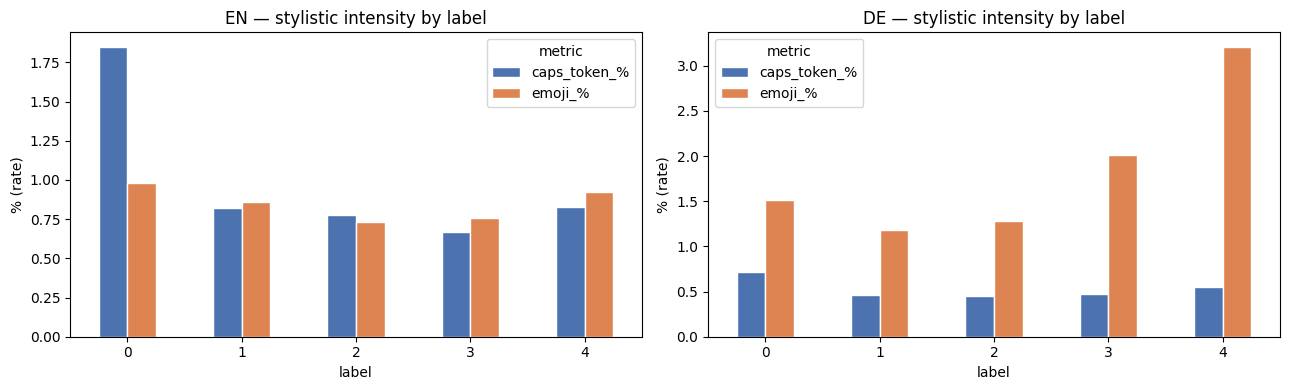

metric       caps_token_%  emoji_%
_lang label                       
DE    0             0.721     1.51
      1             0.467     1.18
      2             0.453     1.28
      3             0.477     2.01
      4             0.549     3.21
EN    0             1.849     0.98
      1             0.819     0.86
      2             0.778     0.73
      3             0.666     0.76
      4             0.826     0.92

In [13]:
emoji_rates = analyzer.special_rates(debug, "sentence", group_col=["_lang", "label"])
caps_rates  = analyzer.caps_word_rate(debug, "sentence", group_cols=["_lang", "label"])

emoji_long = (emoji_rates[["emoji_%"]]
              .reset_index()
              .rename(columns={"emoji_%": "rate"}))
emoji_long["metric"] = "emoji_%"

caps_long = (caps_rates.reset_index()
                       .rename(columns={"caps_token_rate_%": "rate"}))
caps_long["metric"] = "caps_token_%"

combined = pd.concat([emoji_long, caps_long], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, lang in zip(axes, ["EN", "DE"]):
    sub = combined[combined["_lang"] == lang]
    pivoted = sub.pivot(index="label", columns="metric", values="rate")
    pivoted.plot(kind="bar", ax=ax, edgecolor="white",
                 color=["#4C72B0", "#DD8452"])
    ax.set_title(f"{lang} — stylistic intensity by label")
    ax.set_xlabel("label")
    ax.set_ylabel("% (rate)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("data_analysis/img/stylistic_intensity.png", dpi=120, bbox_inches="tight")
plt.show()

display(combined.pivot(index=["_lang", "label"], columns="metric", values="rate"))

### 3.5 Cleaning rule diagnostics

Fraction of raw documents that each cleaning rule would touch — independent
of whether the rule is enabled. Useful as a sanity check on how often each
step actually fires.

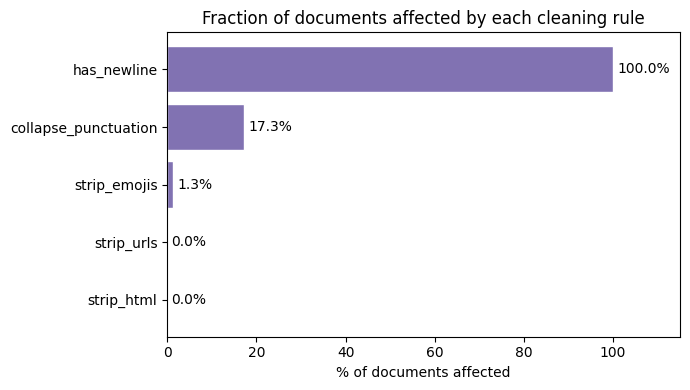

,rule,n_affected,pct_affected
0,strip_html,6,0.00
1,strip_urls,4,0.00
2,strip_emojis,3387,1.34
3,collapse_punctuation,43538,17.28
4,has_newline,252000,100.00


In [14]:
diag = analyzer.rule_diagnostics(debug, text_col='sentence')

fig, ax = plt.subplots(figsize=(7, 4))
diag_s = diag.sort_values('pct_affected')
bars = ax.barh(diag_s['rule'], diag_s['pct_affected'], color='#8172B2', edgecolor='white')
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_xlabel('% of documents affected')
ax.set_title('Fraction of documents affected by each cleaning rule')
ax.set_xlim(0, diag_s['pct_affected'].max() * 1.15)
plt.tight_layout()
plt.savefig('data_analysis/img/rule_diagnostics.png', dpi=120, bbox_inches='tight')
plt.show()

display(diag)
